# 03 · Análise exploratória da cafeicultura

**Coffee Big Data Intelligence**

Responde, de forma descritiva, a duas perguntas: **quais regiões têm maior produtividade?** e **como a produção evoluiu?** Fonte: IBGE/PAM (real). Todo número vem do código; nada é digitado.

**Regras:** arábica e canephora **não** são misturados quando há desagregação (2012+); séries 1974–2011 são rotuladas "total (espécies não separadas)"; produtividade regional é sempre **ponderada por área** (Σ produção / Σ área), nunca média simples de rendimentos.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from coffeebdi import config, silver, modeling as M, quality
from coffeebdi.lake import Lake
from coffeebdi.nbutils import duck, mpl_style

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:,.2f}".format)
mpl_style()
lake = Lake()
con = duck(lake)
def q(sql):
    """Executa SQL (DuckDB) sobre as tabelas silver/gold e devolve DataFrame."""
    return con.execute(sql).df()
FIG = config.OUTPUTS / "figures"

## 1. Evolução em São Paulo (1974–2025) — série *total*

Pico de produção: 1981 (1,218 mil t) | 2025: 316 mil t
Área colhida: 641 mil ha (1974) → 194 mil ha (2025): variação -70%
Rendimento, ponta a ponta: 1,810 kg/ha (1974) → 1,634 kg/ha (2025): variação -10%
Rendimento, média de 5 anos: 1,287 kg/ha (1974–78) → 1,618 kg/ha (2021–25): variação 26%


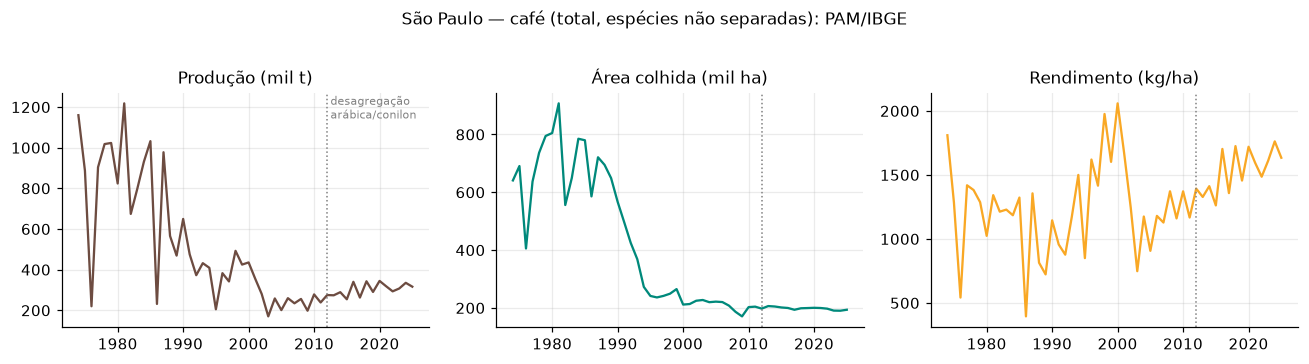

In [2]:
sp = q('''
SELECT ano, quantidade_t/1e3 AS prod_kt, area_colhida_ha/1e3 AS area_kha, rendimento_kg_ha
FROM pam_uf WHERE uf = 'SP' AND especie = 'total' ORDER BY ano''')
pk = sp.loc[sp.prod_kt.idxmax()]
print(f"Pico de produção: {int(pk.ano)} ({pk.prod_kt:,.0f} mil t) | 2025: {sp.prod_kt.iloc[-1]:,.0f} mil t")
a0, a1 = sp.set_index('ano').area_kha.loc[[1974, 2025]]
print(f"Área colhida: {a0:,.0f} mil ha (1974) → {a1:,.0f} mil ha (2025): variação {100*(a1/a0-1):.0f}%")
y0, y1 = sp.set_index('ano').rendimento_kg_ha.loc[[1974, 2025]]
print(f"Rendimento, ponta a ponta: {y0:,.0f} kg/ha (1974) → {y1:,.0f} kg/ha (2025): variação {100*(y1/y0-1):.0f}%")
m0 = sp[sp.ano.between(1974, 1978)].rendimento_kg_ha.mean(); m1 = sp[sp.ano.between(2021, 2025)].rendimento_kg_ha.mean()
print(f"Rendimento, média de 5 anos: {m0:,.0f} kg/ha (1974–78) → {m1:,.0f} kg/ha (2021–25): variação {100*(m1/m0-1):.0f}%")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, c, t, col in zip(ax, ["prod_kt", "area_kha", "rendimento_kg_ha"], ["Produção (mil t)", "Área colhida (mil ha)", "Rendimento (kg/ha)"], ["#6d4c41", "#00897b", "#f9a825"]):
    a.plot(sp.ano, sp[c], color=col); a.set_title(t); a.axvline(2012, color="grey", ls=":", lw=1)
ax[0].text(2012.5, ax[0].get_ylim()[1]*.9, "desagregação\narábica/conilon", fontsize=7, color="grey")
fig.suptitle("São Paulo — café (total, espécies não separadas): PAM/IBGE", y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "03_sp_evolucao.png"); plt.show()

**Como ler:** três painéis de uma mesma série. A linha pontilhada marca 2012, quando a PAM passa a separar arábica de canephora. A produção e a **área colhida** caem muito desde o pico (números impressos acima). **Armadilha da comparação ponta a ponta:** por causa da **bienalidade** (o cafeeiro alterna anos de carga alta e baixa), comparar só 1974 com 2025 pode enganar; a **média de 5 anos** é um comparador mais justo, e nela o rendimento paulista aparece *maior* hoje. Esse aumento junto com a redução de área pode refletir tecnologia, renovação e abandono das lavouras menos produtivas — **efeitos que a série agregada não separa**.

## 2. SP no contexto nacional (2012+ — arábica e canephora separados)

In [3]:
nac = q('''
SELECT uf, especie, quantidade_t FROM pam_uf WHERE ano = 2025 AND especie IN ('arabica','canephora') AND quantidade_t > 0''')
nac = nac.pivot_table(index="uf", columns="especie", values="quantidade_t", aggfunc="sum").fillna(0)
nac["total_t"] = nac.sum(axis=1)
nac["% arábica na UF"] = 100 * nac["arabica"] / nac["total_t"]
nac["% do Brasil"] = 100 * nac["total_t"] / nac["total_t"].sum()
nac.sort_values("total_t", ascending=False).head(8).round(1)

especie,arabica,canephora,total_t,% arábica na UF,% do Brasil
uf,,,,,
MG,"1,534,674.00","29,398.00","1,564,072.00",98.10,44.90
ES,"198,941.00","871,358.00","1,070,299.00",18.60,30.70
SP,"316,196.00",166.00,"316,362.00",99.90,9.10
BA,"92,439.00","187,268.00","279,707.00",33.00,8.00
RO,0.00,"145,746.00","145,746.00",0.00,4.20
PR,"43,820.00",0.00,"43,820.00",100.00,1.30
RJ,"25,675.00",216.00,"25,891.00",99.20,0.70
GO,"16,658.00",0.00,"16,658.00",100.00,0.50


**Interpretação:** a tabela mostra a **especialização** de cada UF. Estados capixaba/rondoniense produzem majoritariamente canephora; MG, SP e PR, arábica. **Misturar espécies na análise de produtividade compararia culturas diferentes** (ordem de grandeza distinta de rendimento) — por isso o foco em SP-arábica.

## 3. Produtividade municipal (arábica) — onde é maior?

Janela: média ponderada de **2023–2025**; só municípios com área colhida média ≥ 100 ha (rendimento de áreas minúsculas é instável).

In [4]:
mun = q('''
SELECT m.cod_ibge, d.municipio, d.microrregiao, d.mesorregiao,
       sum(m.quantidade_t) AS prod_t, sum(m.area_colhida_ha) AS area_ha,
       1000 * sum(m.quantidade_t) / sum(m.area_colhida_ha) AS rend_kg_ha,
       avg(m.area_colhida_ha) AS area_media_ha, count(DISTINCT m.rendimento_kg_ha) AS valores_distintos
FROM pam_municipio m JOIN dim_municipio d USING (cod_ibge)
WHERE m.especie = 'arabica' AND m.ano BETWEEN 2023 AND 2025 AND m.area_colhida_ha > 0
GROUP BY 1, 2, 3, 4 HAVING avg(m.area_colhida_ha) >= 100''')
mun["sacas_por_ha"] = mun["rend_kg_ha"] / 60
print(f"Municípios elegíveis: {len(mun)} | rendimento SP-arábica 2023–25 (ponderado): {1000*mun.prod_t.sum()/mun.area_ha.sum():,.0f} kg/ha")
top = mun.sort_values("rend_kg_ha", ascending=False).head(12)
top[["municipio", "microrregiao", "area_media_ha", "prod_t", "rend_kg_ha", "sacas_por_ha", "valores_distintos"]].round(1)

Municípios elegíveis: 119 | rendimento SP-arábica 2023–25 (ponderado): 1,679 kg/ha


,municipio,microrregiao,area_media_ha,prod_t,rend_kg_ha,sacas_por_ha,valores_distintos
21,Trabiju,Araraquara,183.30,"1,880.00","3,418.20",57.00,2
28,Tejupá,Ourinhos,"4,433.30","44,350.00","3,334.60",55.60,2
2,Nuporanga,São Joaquim da Barra,552.00,"4,813.00","2,906.40",48.40,2
0,Araraquara,Araraquara,108.30,883.00,"2,716.90",45.30,3
81,Orlândia,São Joaquim da Barra,393.00,"2,962.00","2,512.30",41.90,3
22,Buritizal,Ituverava,458.00,"3,194.00","2,324.60",38.70,3
102,Igarapava,Ituverava,106.00,734.00,"2,308.20",38.50,3
115,Jeriquara,Franca,"4,900.00","33,270.00","2,263.30",37.70,2
57,Duartina,Bauru,783.30,"5,270.00","2,242.60",37.40,3
109,Fartura,Ourinhos,"2,488.00","16,442.00","2,202.80",36.70,2


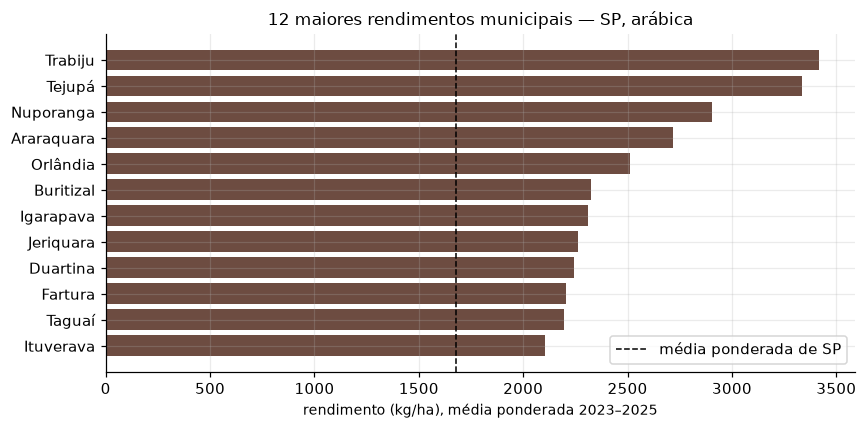

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
t = top.iloc[::-1]
ax.barh(t.municipio, t.rend_kg_ha, color="#6d4c41")
ax.axvline(1000 * mun.prod_t.sum() / mun.area_ha.sum(), color="k", ls="--", lw=1, label="média ponderada de SP")
ax.set(xlabel="rendimento (kg/ha), média ponderada 2023–2025", title="12 maiores rendimentos municipais — SP, arábica"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "03_top_rendimento.png"); plt.show()

**Como ler:** barras = rendimento ponderado de cada município; linha tracejada = média paulista. **Cautela com a coluna `valores_distintos`**: se for 1 nos três anos, o rendimento é uma estimativa repetida (notebook 02). Um município no topo do ranking com valor repetido tem **menor confiança** do que um com valores que variam ano a ano. Ranking = *descrição*, não prova de "melhor manejo" — altitude, cultivar, irrigação e idade da lavoura (não observados aqui) explicam muito.

## 4. Concentração da produção

2025: 263 municípios produtores de arábica | top-5 = 30.7% | top-10 = 47.8% | top-20 = 66.5% | Gini = 0.85


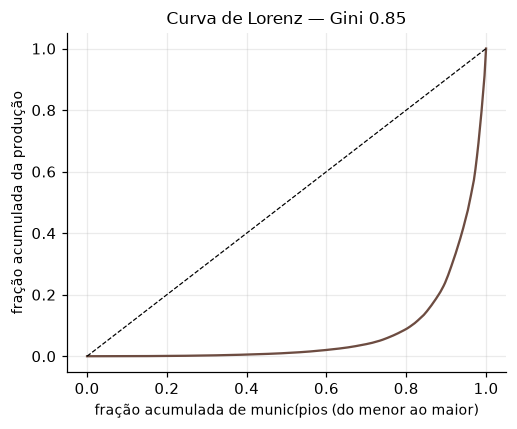

In [6]:
p25 = q('''SELECT cod_ibge, quantidade_t FROM pam_municipio WHERE especie = 'arabica' AND ano = 2025 AND quantidade_t > 0''').sort_values("quantidade_t", ascending=False)
share = p25.quantidade_t / p25.quantidade_t.sum()
x = np.sort(p25.quantidade_t.values); lorenz = np.insert(np.cumsum(x) / x.sum(), 0, 0)
gini = 1 - (lorenz[1:] + lorenz[:-1]).sum() / len(x)     # 1 − 2·área sob Lorenz (regra do trapézio)
print(f"2025: {len(p25)} municípios produtores de arábica | top-5 = {100*share.head(5).sum():.1f}% | top-10 = {100*share.head(10).sum():.1f}% | top-20 = {100*share.head(20).sum():.1f}% | Gini = {gini:.2f}")
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.plot(np.linspace(0, 1, len(lorenz)), lorenz, color="#6d4c41"); ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.set(xlabel="fração acumulada de municípios (do menor ao maior)", ylabel="fração acumulada da produção", title=f"Curva de Lorenz — Gini {gini:.2f}")
plt.tight_layout(); plt.savefig(FIG / "03_lorenz.png"); plt.show()

**Como ler:** quanto mais a curva se afasta da diagonal, mais concentrada a produção. Poucos municípios respondem por grande parte do volume paulista — relevante para **cooperativas e empresas** (risco e logística concentrados).

## 5. Regiões (microrregiões IBGE)

In [7]:
reg = q('''
SELECT d.microrregiao, d.mesorregiao, sum(m.quantidade_t) AS prod_t, sum(m.area_colhida_ha) AS area_ha,
       1000 * sum(m.quantidade_t) / sum(m.area_colhida_ha) AS rend_kg_ha, count(DISTINCT m.cod_ibge) AS municipios
FROM pam_municipio m JOIN dim_municipio d USING (cod_ibge)
WHERE m.especie = 'arabica' AND m.ano BETWEEN 2023 AND 2025 AND m.area_colhida_ha > 0
GROUP BY 1, 2 HAVING sum(m.area_colhida_ha) > 1000 ORDER BY prod_t DESC''')
reg["% da produção de SP"] = 100 * reg.prod_t / reg.prod_t.sum()
reg.head(10).round(1)

,microrregiao,mesorregiao,prod_t,area_ha,rend_kg_ha,municipios,% da produção de SP
0,Franca,Ribeirão Preto,"308,436.00","173,167.00","1,781.10",10,32.40
1,São João da Boa Vista,Campinas,"192,193.00","120,768.00","1,591.40",14,20.20
2,Batatais,Ribeirão Preto,"111,585.00","62,650.00","1,781.10",6,11.70
3,Ourinhos,Assis,"104,776.00","45,601.00","2,297.70",15,11.00
4,Marília,Marília,"69,696.00","54,958.00","1,268.20",13,7.30
5,Amparo,Campinas,"33,648.00","21,762.00","1,546.20",8,3.50
6,Jaú,Bauru,"17,686.00","12,438.00","1,421.90",10,1.90
7,Adamantina,Presidente Prudente,"12,452.00","10,997.00","1,132.30",12,1.30
8,Bauru,Bauru,"11,697.00","6,864.00","1,704.10",14,1.20
9,Avaré,Bauru,"10,864.00","7,826.00","1,388.20",7,1.10


## 6. Altitude e produtividade (descritivo)

`elev_m` é a elevação **média da célula de 0,5°×0,625°** do NASA POWER (~55 km) — não a altitude da lavoura. Serve só como proxy grosseiro de relevo.

Spearman(elevação da célula, rendimento 2023–25) = 0.43 (p=0.000, n=122 municípios) — associação, não causalidade


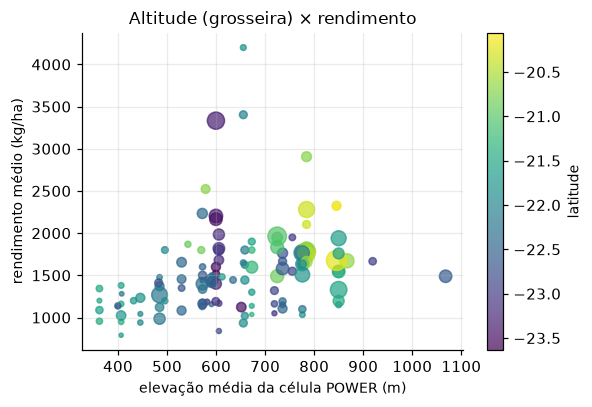

In [8]:
from scipy import stats
pn = q("select * from painel_cafe_arabica where elegivel_modelo and ano between 2023 and 2025")
agg = pn.groupby("cod_ibge").agg(rend=("rendimento_kg_ha", "mean"), elev=("elev_m", "first"), lat=("lat", "first"), lon=("lon", "first"), prod=("quantidade_t", "sum")).dropna()
rho, p = stats.spearmanr(agg.elev, agg.rend)
print(f"Spearman(elevação da célula, rendimento 2023–25) = {rho:.2f} (p={p:.3f}, n={len(agg)} municípios) — associação, não causalidade")
fig, ax = plt.subplots(figsize=(5.5, 3.8))
sc = ax.scatter(agg.elev, agg.rend, s=np.sqrt(agg["prod"]) * .6, c=agg.lat, cmap="viridis", alpha=.7)
ax.set(xlabel="elevação média da célula POWER (m)", ylabel="rendimento médio (kg/ha)", title="Altitude (grosseira) × rendimento"); plt.colorbar(sc, label="latitude")
plt.tight_layout(); plt.savefig(FIG / "03_altitude_rendimento.png"); plt.show()

**Interpretação agronômica (hipótese):** o arábica tende a preferir altitudes e temperaturas mais amenas, e a elevação está correlacionada com a latitude/região no estado; por isso a associação mistura **vários fatores** (clima, tecnologia, tradição regional). Com uma célula de ~55 km a "altitude" é muito grosseira — **não use este gráfico para concluir sobre altitude de talhões**.

## 7. Mapa interativo (centróides municipais)

In [9]:
import plotly.express as px
mp = pn.groupby("cod_ibge").agg(municipio=("municipio", "first"), lat=("lat", "first"), lon=("lon", "first"),
                                prod=("quantidade_t", "mean"), rend=("rendimento_kg_ha", "mean")).reset_index()
fig = px.scatter_geo(mp, lat="lat", lon="lon", size="prod", color="rend", hover_name="municipio", color_continuous_scale="YlOrBr",
                     size_max=22, scope="south america", title="Produção média 2023–25 (tamanho) e rendimento (cor) — arábica, SP")
fig.update_geos(lataxis_range=[-25.6, -19.5], lonaxis_range=[-53.5, -44], showcountries=True, showsubunits=True)
(config.OUTPUTS / "plots").mkdir(exist_ok=True)
fig.write_html(config.OUTPUTS / "plots" / "03_mapa_producao.html", include_plotlyjs="cdn")
fig.show()

**Como ler:** cada bolha é um município (centróide IBGE); tamanho = produção média; cor = rendimento médio. O HTML interativo fica em `outputs/plots/03_mapa_producao.html`.

## 8. Valor da produção em reais constantes

O valor da PAM é nominal ("mil reais da época"). Para comparar anos usamos o IPCA (base: média de 2025). **Só de 1994 em diante** (antes, moedas diferentes).

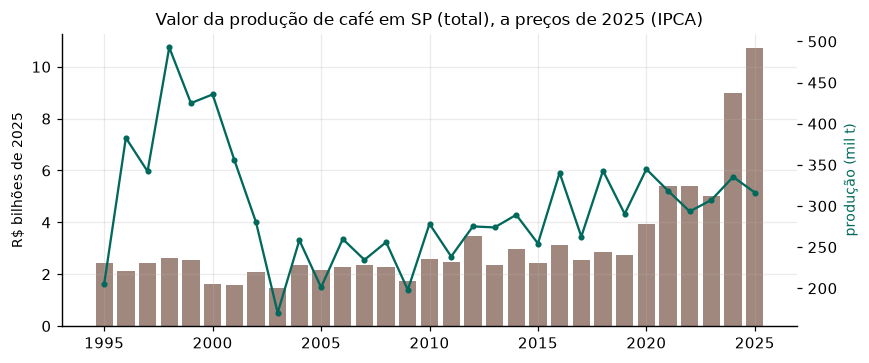

ano                 2020  2021  2022  2023  2024  2025
valor_real_bi_2025  3.94  5.39  5.38  5.01  8.98 10.72


In [10]:
val = q('''
SELECT u.ano, u.valor_mil_reais, u.quantidade_t, i.fator_nominal_para_real,
       u.valor_mil_reais / i.fator_nominal_para_real / 1e6 AS valor_real_bi_2025
FROM pam_uf u JOIN ipca_anual i USING (ano)
WHERE u.uf = 'SP' AND u.especie = 'total' AND u.ano >= 1995 ORDER BY u.ano''')
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(val.ano, val.valor_real_bi_2025, color="#a1887f"); ax.set(ylabel="R$ bilhões de 2025", title="Valor da produção de café em SP (total), a preços de 2025 (IPCA)")
ax2 = ax.twinx(); ax2.plot(val.ano, val.quantidade_t / 1e3, color="#00695c", marker="o", ms=3); ax2.set_ylabel("produção (mil t)", color="#00695c"); ax2.grid(False)
plt.tight_layout(); plt.savefig(FIG / "03_valor_real.png"); plt.show()
print(val.set_index("ano")[["valor_real_bi_2025"]].tail(6).round(2).T)

**Como ler:** barras = valor real (eixo esquerdo); linha = produção (direito). O valor depende de **volume × preço**: anos de baixa produção podem ter valor alto se o preço sobe. Efeito do **IPCA** como deflator é uma escolha (café tem seu próprio ciclo de preços).

## 9. Exercícios
1. Refaça o ranking da seção 3 com janela 2013–2015. Quais municípios permanecem no topo? O que isso sugere sobre estabilidade dos rankings?
2. Calcule o Gini da **área** colhida (em vez da produção). A concentração é maior em área ou em produção?
3. Troque o filtro de 100 ha por 30 ha e 300 ha. Como o ranking e o rendimento médio ponderado mudam?